# Chapitre 5 - Cours 3 : réplication multi-leader et conflits

Avec un leader unique, toute écriture passe par un seul nœud : si on ne peut pas le
joindre, on ne peut pas écrire. Autoriser **plusieurs** nœuds à accepter des écritures
lève cette limite, mais fait apparaître le problème central de ce cours : des écritures
**concurrentes** sur des leaders différents, qu'il faut réconcilier. Il couvre la
section *Multi-Leader Replication* : *Use Cases for Multi-Leader Replication*, *Handling Write Conflicts* et *Multi-Leader Replication Topologies*.

**Plan.**

1. Plusieurs leaders : pourquoi seulement en asynchrone.
2. Le fonctionnement multi-centres de données : latence, pannes, cohérence.
3. Topologies de réplication et messages qui se doublent.
4. Les conflits d'écriture : d'où ils viennent, combien il y en a.
5. Éviter les conflits.
6. Le dernier écrivain gagne... et les autres disparaissent.
7. Garder les frères : résolution par l'application.
8. Converger vers un état cohérent.
9. Qu'est-ce qu'un conflit ?

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import replication as rp
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)

## 1. Plusieurs leaders (section *Multi-Leader Replication*)

Extension naturelle du leader unique : plusieurs nœuds acceptent les écritures, et chacun
transmet ses modifications à tous les autres ; chaque leader est en même temps suiveur des
autres. On parle aussi de réplication **active/active** ou **bidirectionnelle**.

Si la réplication entre leaders était **synchrone**, une écriture sur A attendrait B ; une
coupure entre A et B bloquerait les écritures sur A : on retrouverait exactement un leader
unique (B) auquel A ne ferait que relayer les requêtes. Tout l'intérêt est donc dans la
version **asynchrone**, où chaque leader traite ses écritures même coupé des autres.

Le multi-leader est souvent une fonction **rajoutée** à une base qui n'a pas été conçue
pour elle (MySQL, Oracle, SQL Server, extensions comme pglogical pour PostgreSQL) : les
clés auto-incrémentées, les déclencheurs et les contraintes d'intégrité y interagissent
mal. Beaucoup le considèrent comme un terrain dangereux, à éviter si possible.

> **À retenir.** Le multi-leader n'a de sens qu'en asynchrone : chaque leader écrit
> localement et propage plus tard. Le prix à payer : des écritures concurrentes à
> réconcilier.

## 2. Le fonctionnement multi-centres de données (section *Multi-datacenter operation*)

Le cas d'usage typique : une base répliquée dans plusieurs centres de données éloignés, pour
survivre à la perte de l'un d'eux ou être proche des utilisateurs. Avec un leader unique,
toutes les écritures traversent la planète jusqu'au leader. Avec le multi-leader, chaque
centre de données a son leader et ses suiveurs, et seuls les leaders échangent entre eux.

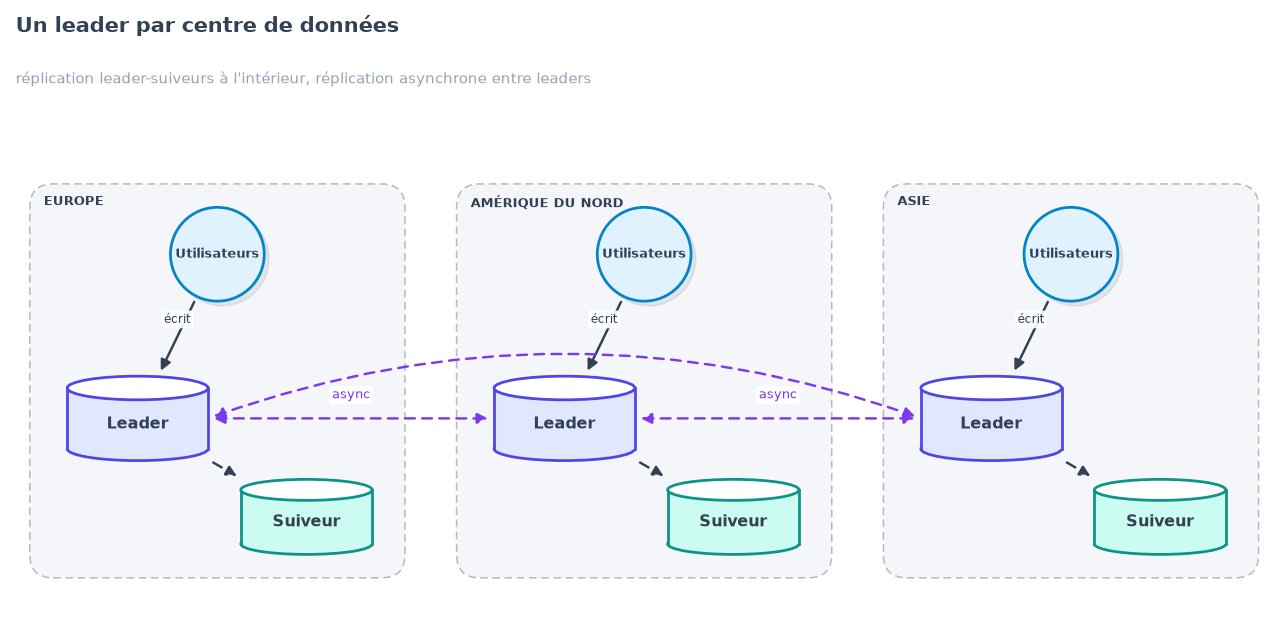

In [2]:
d = Diagram(13.5, 5.4, title="Un leader par centre de données",
            subtitle="réplication leader-suiveurs à l'intérieur, réplication asynchrone entre leaders")
sites = [("eu", 2.2, "Europe"), ("us", 6.75, "Amérique du Nord"), ("as", 11.3, "Asie")]
for key, x, nom in sites:
    d.group(x - 2.0, 0.3, x + 2.0, 4.5, nom, color=SLATE)
    d.box(f"u{key}", x, 3.75, "Utilisateurs", kind="user", w=1.0, color=SKY, fontsize=8.5)
    d.box(f"L{key}", x - 0.85, 2.0, "Leader", color=INDIGO, kind="db", w=1.5)
    d.box(f"F{key}", x + 0.95, 0.95, "Suiveur", color=TEAL, kind="db", w=1.4, h=0.8)
    d.arrow(f"u{key}", f"L{key}", "écrit", fontsize=8)
    d.arrow(f"L{key}", f"F{key}", style="dashed")
d.arrow("Leu", "Lus", "async", color=VIOLET, style="dashed", both=True, label_offset=(0, 0.25))
d.arrow("Lus", "Las", "async", color=VIOLET, style="dashed", both=True, label_offset=(0, 0.25))
d.arrow("Leu", "Las", color=VIOLET, style="dashed", both=True, rad=-0.18)
d.show()

Le livre compare les deux configurations selon quatre critères :

- **performance** : en leader unique, chaque écriture paie un aller-retour vers le
  centre de données du leader ; en multi-leader, elle est traitée localement et le délai
  inter-sites est caché à l'utilisateur ;
- **panne d'un centre de données** : le leader unique impose un basculement ; en multi-leader,
  chaque site continue seul et la réplication rattrape au retour ;
- **problèmes réseau** : le lien inter-sites est moins fiable qu'un réseau local ; le leader
  unique y est très sensible (chaque écriture distante le traverse), le multi-leader
  asynchrone le tolère ;
- **cohérence** : c'est le point faible du multi-leader (voir plus bas).

**La performance, chiffrée.** Prenons des allers-retours réseau typiques entre trois
sites et une répartition des utilisateurs 40 % Europe, 35 % Amérique, 25 % Asie.

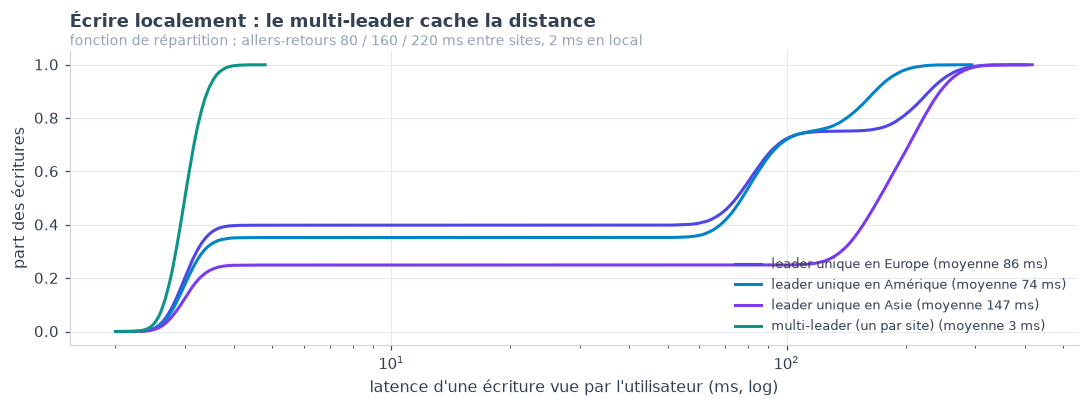

,Europe,Amérique,Asie
Europe,2,80,220
Amérique,80,2,160
Asie,220,160,2


In [3]:
regions = ["Europe", "Amérique", "Asie"]
RTT = pd.DataFrame([[2, 80, 220], [80, 2, 160], [220, 160, 2]], index=regions, columns=regions)
part = np.array([0.40, 0.35, 0.25])
n = 100000
user_reg = rng.choice(3, n, p=part)
jitter = rng.lognormal(0, 0.15, n)
commit = 1.0
res = {}
for lead in range(3):
    res[f"leader unique en {regions[lead]}"] = RTT.values[user_reg, lead] * jitter + commit
res["multi-leader (un par site)"] = RTT.values[user_reg, user_reg] * jitter + commit
fig, ax = plt.subplots(figsize=(10, 3.8))
for (lab, lat), c in zip(res.items(), [INDIGO, SKY, VIOLET, TEAL]):
    xs = np.sort(lat)
    ax.plot(xs, np.arange(1, n + 1) / n, color=c, label=f"{lab} (moyenne {lat.mean():.0f} ms)", lw=2)
ax.set_xscale("log")
ax.set_xlabel("latence d'une écriture vue par l'utilisateur (ms, log)"); ax.set_ylabel("part des écritures")
ax.set_title("Écrire localement : le multi-leader cache la distance")
subtitle(ax, "fonction de répartition ; allers-retours 80 / 160 / 220 ms entre sites, 2 ms en local")
ax.legend(loc="lower right", fontsize=8.5)
plt.tight_layout(); plt.show()
RTT

Avec un leader unique en Europe, 60 % des écritures paient 80 à 220 ms ; aucun
emplacement du leader ne descend sous une cinquantaine de millisecondes en moyenne. Le
multi-leader ramène toutes les écritures à quelques millisecondes : c'est la « marche »
des courbes qui disparaît.

**La cohérence, le revers.** Un leader unique peut garantir des transactions
sérialisables (chapitre 7). Deux leaders ne peuvent pas empêcher deux
écritures **chacune valide localement** de violer ensemble une contrainte : un compte qui
passe en négatif, un nom d'utilisateur pris deux fois. Démonstration avec deux leaders
qui vérifient l'unicité **localement** avant d'accepter une inscription.

In [4]:
def inscription(leader, nom, t):
    if nom in leader["noms"]:
        return "refusée (déjà pris)"
    leader["noms"][nom] = t
    return "acceptée"

eu, us = {"noms": {}}, {"noms": {}}
journal = [("Europe", eu, "alice", 0.00), ("Amérique", us, "alice", 0.03), ("Europe", eu, "bob", 0.50),
           ("Amérique", us, "bob", 1.20)]                       # réplication : 0,1 s entre sites
rows = []
repl_delay = 0.1
pending = []
for site, leader, nom, t in journal:
    for (t_arr, dst, nm, t0) in list(pending):                  # applique les réplications arrivées
        if t_arr <= t:
            dst["noms"].setdefault(nm, t0); pending.remove((t_arr, dst, nm, t0))
    verdict = inscription(leader, nom, t)
    rows.append({"instant (s)": t, "site": site, "inscription": nom, "verdict local": verdict})
    if verdict == "acceptée":
        pending.append((t + repl_delay, us if leader is eu else eu, nom, t))
pd.DataFrame(rows)

,instant (s),site,inscription,verdict local
0,0.00,Europe,alice,acceptée
1,0.03,Amérique,alice,acceptée
2,0.50,Europe,bob,acceptée
3,1.20,Amérique,bob,refusée (déjà pris)


`alice` est acceptée deux fois : les deux inscriptions sont arrivées à 30 ms d'intervalle,
avant que la réplication (100 ms) ne fasse connaître la première à l'autre site. `bob`,
inscrit à 0,7 s d'écart, est correctement refusé la seconde fois. C'est une limite
**fondamentale** : pour garantir l'unicité, il faut se coordonner, donc revenir à un
leader unique (ou à un consensus) pour ces écritures-là.

### Deux autres cas d'usage (section *Use Cases for Multi-Leader Replication*)

- **Clients qui fonctionnent hors ligne.** L'agenda de votre téléphone, de votre
  ordinateur portable et de votre ordinateur de bureau doit rester utilisable sans
  connexion. Chaque appareil a une base locale qui joue le rôle de leader, et une
  réplication multi-leader asynchrone (la synchronisation) les réconcilie quand le réseau
  revient, avec un retard qui peut atteindre des heures ou des jours. Architecturalement,
  c'est le fonctionnement multi-centres de données poussé à l'extrême : chaque appareil est un
  « centre de données », relié aux autres par un réseau très peu fiable. CouchDB est
  conçu pour ce mode de fonctionnement.
- **Édition collaborative en temps réel.** Dans Etherpad ou Google Docs, chaque
  utilisateur modifie sa copie locale, et les modifications sont répliquées de façon
  asynchrone vers les autres. Pour éviter tout conflit, on pourrait verrouiller le
  document (un seul éditeur à la fois), ce qui revient à un leader unique ; pour une
  collaboration fluide, on rend l'unité de modification très petite (une frappe) et on
  accepte des conflits, résolus automatiquement (section 8).

> **À retenir.** Un leader par centre de données rend les écritures locales et résiste aux
> pannes de site et de liens, mais aucune contrainte globale (unicité, solde positif) ne
> peut être garantie sans coordination.